# Short-Recording Input-Policy Diagnostic

## Summary

On the same **102 architecture-compatible short recordings**, native input produces **34/102 correct (33.33%)**, versus **28/102 (27.45%)** for the original right-zero-padded input. The paired difference is **+5.88 pp**, conditional 95% recording-bootstrap interval **[−0.98, +12.75]**. The interval spans zero; the observed gain is uncertain.

Native input changes 46 predictions, with 10 repairs and four new errors. Left-padding changes 50 predictions on this same subset, while its accuracy is 26.47%. This demonstrates sensitivity to input policy without identifying a single internal padding mechanism. **The original external benchmark remains 45.17% on 259 recordings. No replacement policy is selected.**

The fixed one-pass inference completed on Colab Tesla T4 in 23.98 seconds, excluding setup/downloads, with zero fits. This notebook displays the completed evidence and can repeat the frozen protocol on a fresh GPU runtime; completed outputs are reused.

## Context and fixed protocol

This study uses a within-recording input-length probe. The [protocol](../reports/duration_probe_20261105/protocol.json) was fixed before new policy predictions. The original FSD panel is already exposed, so these are **explanatory diagnostic results**, not independent confirmation of a newly selected model.

| Policy | Treatment | Population |
| --- | --- | --- |
| Right pad | Original waveform followed by zeros, total five seconds | All 105 short recordings; primary comparison uses eligible 102 |
| Native | Original waveform at its actual length; no padding | Exactly 102 compatible recordings |
| Left pad | Zeros followed by the original waveform, total five seconds | All 105; also reported on eligible 102 |

The same frozen Cnn14_16k, original training scaler and logistic head are used. All 50 ESC-50 output classes compete, with no remapping or refitting. No gain normalization, repeated audio, waveform truncation, silence trimming or augmentation is introduced.

### Architectural minimum and controls

The [official model](https://github.com/qiuqiangkong/audioset_tagging_cnn/blob/master/pytorch/models.py) uses a centered STFT with hop 160 samples, five time-pooling stages of factor two, and global temporal max-plus-mean pooling. At 16 kHz, the number of STFT frames is `1 + floor(N/160)`. Five pooling stages require at least 32 frames, hence **N ≥ 4,960 samples = 0.31 seconds**. Three shorter recordings are excluded only from native inference and remain in the original benchmark.

The original 105 right-padded predictions are replayed before interventions, requiring unchanged labels and maximum absolute probability difference ≤0.001. Ten predetermined full five-second windows are processed by both input paths as identical-input controls. These controls compare paths with each other, not with previous whole-recording aggregate predictions.

Primary inference: native-minus-right accuracy on the same 102 recording IDs, with 4,000 paired recording-level bootstrap resamples. Secondary placement and class comparisons are descriptive without multiplicity adjustment. Input duration also changes convolution boundaries and pooling statistics; it does not isolate a pure padding effect. Classifier confidence is not treated as calibration.

In [1]:
from pathlib import Path
import os,sys,subprocess,json,zipfile,csv
from datetime import datetime,timezone
RUN_PROBE=True
candidates=[Path.cwd(),Path.cwd().parent,Path.cwd()/"research/esc50_improvements",Path("/content/esc50_duration")]
ROOT=next((p for p in candidates if (p/"scripts/run_duration_probe.py").exists()),None)
if ROOT is None:
    ROOT=Path("/content/esc50_duration")
    subprocess.run(["git","clone","--depth","1","https://github.com/Richardafcs/esc-50-sound-classification.git",str(ROOT)],check=True,capture_output=True,timeout=180)
os.chdir(ROOT);sys.path[:0]=[str(ROOT),str(ROOT/"src")]
DATA=ROOT/"reports/duration_probe_20261105";OUT=ROOT/"results/runs/duration_probe_20261105"
ASSETS=Path("/content/esc50_duration_assets") if Path("/content").exists() else ROOT/"results/duration_assets"
print("Notebook execution (UTC):",datetime.now(timezone.utc).isoformat());print("Project:",ROOT.name)

Notebook execution (UTC): 2026-11-05T09:40:43.881377+00:00
Project: esc50_duration


In [2]:
subprocess.run([sys.executable,"-m","pip","install","-q","torchlibrosa==0.1.0","librosa==0.11.0","soundfile>=0.13","scikit-learn==1.6.1","pandas>=2.2","matplotlib>=3.9"],check=True,capture_output=True,timeout=360)
import numpy as np,pandas as pd,torch
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
plt.rcParams.update({"font.size":11,"figure.figsize":(10,5),"axes.spines.top":False,"axes.spines.right":False})
def table(frame,precision=2):display(frame.style.format(precision=precision,na_rep="—").hide(axis="index"))
print("Runtime:",torch.__version__,np.__version__,torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Runtime: 2.11.0+cu130 2.4.6 Tesla T4


## Recordings and exclusions

Only recording duration and the architecture rule determine eligibility. The three exclusions were identified before new predictions, not from their model outcomes.

In [3]:
manifest=pd.read_csv(DATA/"short_recordings.csv")
counts=manifest.groupby("category").agg(short_recordings=("filename","size"),native_eligible=("native_eligible","sum")).reset_index()
table(counts);table(manifest[~manifest.native_eligible][["filename","category","samples","seconds"]],6)
print("Short recordings:",len(manifest),"Primary paired population:",manifest.native_eligible.sum())

category,short_recordings,native_eligible
clapping,42,40
engine,8,8
fireworks,20,20
footsteps,16,15
rain,6,6
wind,13,13


filename,category,samples,seconds
76187.wav,footsteps,4887,0.305437
384141.wav,clapping,4895,0.305937
384155.wav,clapping,4843,0.302687


Short recordings: 105 Primary paired population: 102


## Execute the fixed diagnostic

A fresh run needs a GPU, the original published head and the official FSD test audio/PANNs backbone. Only the 105 short recordings and ten long-recording controls are extracted. The saved original PANNs probability matrix is included for numerical replay. Raw audio and the large backbone are not redistributed.

In [4]:
if RUN_PROBE and not (OUT/"summary.json").exists():
    if not torch.cuda.is_available():raise RuntimeError("Select a Colab GPU or set RUN_PROBE=False for saved results.")
    from concurrent.futures import ThreadPoolExecutor
    ASSETS.mkdir(parents=True,exist_ok=True);repository=ASSETS/"audioset_tagging_cnn"
    if not repository.exists():subprocess.run(["git","clone","--depth","1","https://github.com/qiuqiangkong/audioset_tagging_cnn.git",str(repository)],check=True,capture_output=True,timeout=180)
    def acquire(item):
        name,url=item;target=ASSETS/name
        if not target.exists():
            temporary=target.with_suffix(target.suffix+".part")
            subprocess.run(["curl","-fsSL","--retry","2","--max-time","600","-o",str(temporary),url],check=True,capture_output=True,timeout=650);temporary.replace(target)
    with ThreadPoolExecutor(max_workers=2) as workers:list(workers.map(acquire,[("Cnn14_16k_mAP=0.438.pth","https://zenodo.org/records/3987831/files/Cnn14_16k_mAP%3D0.438.pth?download=1"),("FSDnoisy18k.audio_test.zip","https://zenodo.org/records/2529934/files/FSDnoisy18k.audio_test.zip?download=1")]))
    wanted=set(manifest.filename)|set(pd.read_csv(DATA/"full_window_controls.csv").filename)
    audio=ASSETS/"audio";audio.mkdir(exist_ok=True)
    with zipfile.ZipFile(ASSETS/"FSDnoisy18k.audio_test.zip") as zipped:
        for member in zipped.infolist():
            name=Path(member.filename).name
            if name in wanted and not member.is_dir():(audio/name).write_bytes(zipped.read(member))
    print("Official inputs ready:",len(wanted),"recordings including controls.")
else:print("Using completed or published diagnostic results.")

Using completed or published diagnostic results.


In [5]:
if RUN_PROBE:
    result=subprocess.run([sys.executable,"scripts/run_duration_probe.py","--assets",str(ASSETS),"--output",str(OUT),"--device","cuda"],capture_output=True,text=True,timeout=1900)
    if result.returncode:raise RuntimeError(result.stdout[-1000:]+result.stderr[-2500:])
    print(result.stdout[-300:])
    import shutil
    for path in OUT.iterdir():
        if path.suffix in (".json",".csv"):shutil.copy2(path,DATA/path.name)
summary=json.loads((DATA/"summary.json").read_text())
print("Original one-pass inference:",round(summary["inference_seconds"],2),"seconds, setup/downloads excluded; fits:",summary["fits"])

Completed fixed duration probe exists; reading saved results.

Original one-pass inference: 23.98 seconds, setup/downloads excluded; fits: 0


## Results on matched populations

Read the primary table across the same 102 recordings. Results on all 105 are shown separately; native accuracy is never compared with a denominator of 105.

In [6]:
metrics=pd.read_csv(DATA/"metrics.csv");paired=metrics[metrics.population=="native_eligible"].copy()
labels={"right_pad":"Right pad · original","native":"Native duration","left_pad":"Left pad · placement control"}
show=paired.copy();show["policy"]=show.policy.map(labels)
for column in ["accuracy","macro_recall","macro_f1","outside_six_rate"]:show[column]*=100
table(show.rename(columns={"accuracy":"Accuracy (%)","macro_recall":"Macro recall (%)","macro_f1":"Six-class macro-F1 (%)","outside_six_rate":"Outside-six (%)"}))
table(metrics[metrics.population=="all_short"][["policy","recordings","correct","accuracy"]],4)

policy,population,recordings,correct,Accuracy (%),Macro recall (%),Six-class macro-F1 (%),Outside-six (%)
Right pad · original,native_eligible,102,28,27.45,31.94,43.98,71.57
Native duration,native_eligible,102,34,33.33,34.29,45.92,57.84
Left pad · placement control,native_eligible,102,27,26.47,27.39,39.42,71.57


policy,recordings,correct,accuracy
right_pad,105,29,0.2762
left_pad,105,27,0.2571


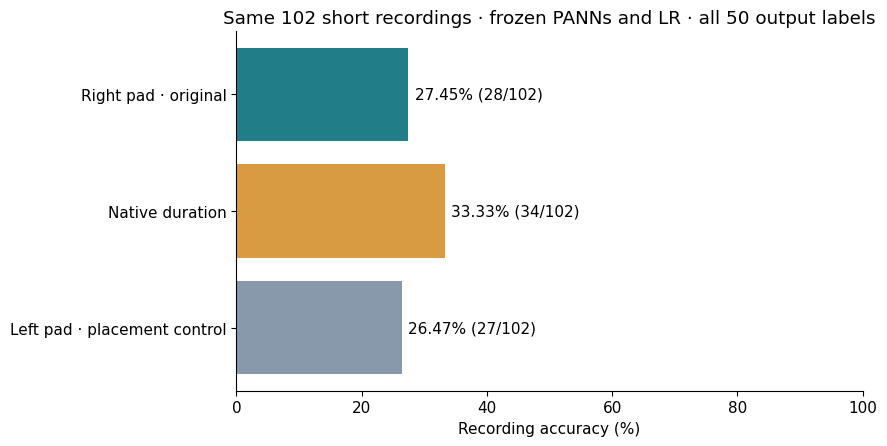

In [7]:
fig,ax=plt.subplots(figsize=(9,4.6));values=100*paired.accuracy.to_numpy()
ax.barh(range(3),values,color=["#217e89","#d89b41","#8799aa"]);ax.set_yticks(range(3),[labels[p] for p in paired.policy]);ax.invert_yaxis();ax.set_xlim(0,100)
for i,(value,row) in enumerate(zip(values,paired.itertuples())):ax.text(value+1,i,f"{value:.2f}% ({row.correct}/{row.recordings})",va="center")
ax.set_xlabel("Recording accuracy (%)");ax.set_title("Same 102 short recordings · frozen PANNs and LR · all 50 output labels")
fig.tight_layout();fig.savefig(DATA/"duration_policy_accuracy.png",dpi=180);plt.show()

comparison,population,recordings,delta_pp,low_pp,high_pp
native_minus_right_pad,native_eligible,102,5.88,-0.98,12.75
left_pad_minus_right_pad,native_eligible,102,-0.98,-7.84,5.88
left_pad_minus_right_pad,all_short,105,-1.90,-8.57,4.76


policy,population,recordings,prediction_flips,both_correct,repairs,new_errors,both_wrong,mean_true_class_probability_change
native,native_eligible,102,46,24,10,4,64,0.06
left_pad,native_eligible,102,50,21,6,7,68,-0.02
left_pad,all_short,105,53,21,6,8,70,-0.02


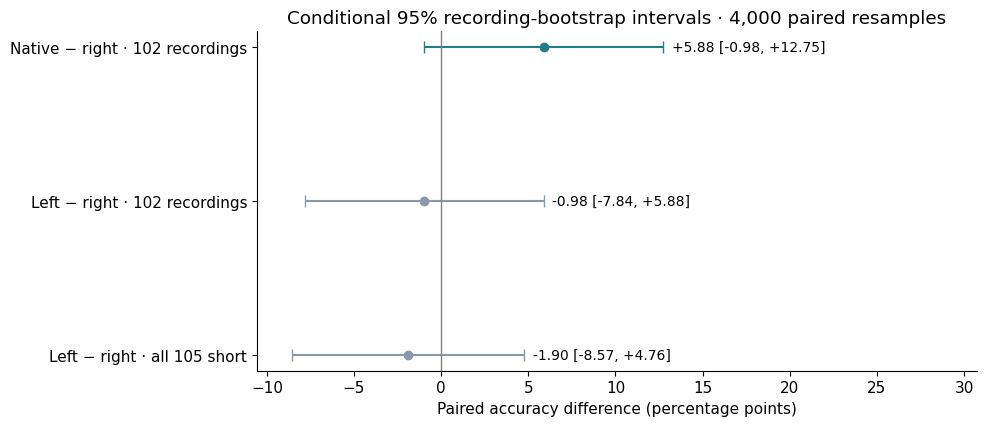

In [8]:
effects=pd.read_csv(DATA/"paired_effects.csv");transitions=pd.read_csv(DATA/"transitions.csv")
table(effects);table(transitions)
fig,ax=plt.subplots(figsize=(10,4.4));names=["Native − right · 102 recordings","Left − right · 102 recordings","Left − right · all 105 short"]
for i,row in effects.iterrows():
    ax.errorbar(row.delta_pp,i,xerr=[[row.delta_pp-row.low_pp],[row.high_pp-row.delta_pp]],fmt="o",capsize=4,color="#217e89" if i==0 else "#8799aa")
    ax.text(row.high_pp+.5,i,f"{row.delta_pp:+.2f} [{row.low_pp:+.2f}, {row.high_pp:+.2f}]",va="center",fontsize=10)
ax.axvline(0,color="gray",linewidth=1);ax.set_yticks(range(3),names);ax.invert_yaxis();ax.set_xlim(min(-2,effects.low_pp.min()-2),effects.high_pp.max()+18)
ax.set_xlabel("Paired accuracy difference (percentage points)");ax.set_title("Conditional 95% recording-bootstrap intervals · 4,000 paired resamples")
fig.tight_layout();fig.savefig(DATA/"duration_policy_effects.png",dpi=180);plt.show()

### Class-level changes

These are small descriptive slices of the eligible 102-recording subset. Input length helps some classes and hurts others; the table does not justify class-specific policy selection.

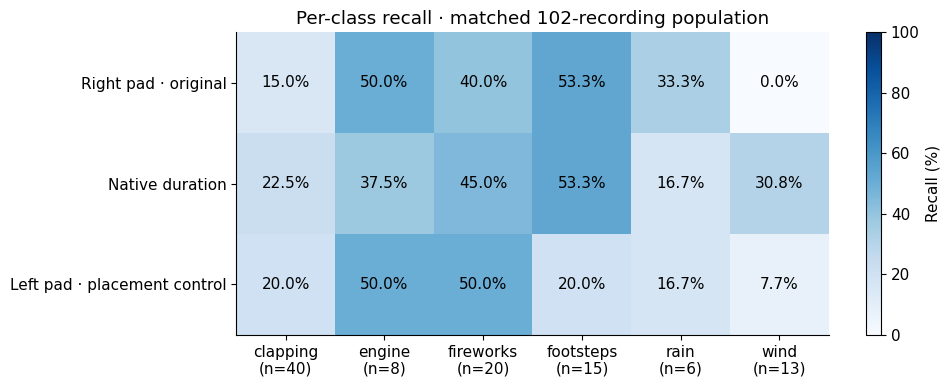

policy,target,category,recordings,recall_percent
right_pad,10,rain,6,33.33
right_pad,16,wind,13,0.00
right_pad,22,clapping,40,15.00
right_pad,25,footsteps,15,53.33
right_pad,44,engine,8,50.00
right_pad,48,fireworks,20,40.00
native,10,rain,6,16.67
native,16,wind,13,30.77
native,22,clapping,40,22.50
native,25,footsteps,15,53.33


In [9]:
per_class=pd.read_csv(DATA/"per_class.csv");matrix=100*per_class.pivot(index="policy",columns="category",values="recall").reindex(["right_pad","native","left_pad"])
counts=per_class[per_class.policy=="native"].set_index("category").recordings
fig,ax=plt.subplots(figsize=(10,4));heat=ax.imshow(matrix.to_numpy(),vmin=0,vmax=100,cmap="Blues",aspect="auto")
ax.set_xticks(range(6),[f"{c}\n(n={counts[c]})" for c in matrix.columns]);ax.set_yticks(range(3),[labels[c] for c in matrix.index])
for i in range(3):
    for j in range(6):
        value=matrix.iloc[i,j];ax.text(j,i,f"{value:.1f}%",ha="center",va="center",color="white" if value>55 else "black")
ax.set_title("Per-class recall · matched 102-recording population");fig.colorbar(heat,ax=ax,label="Recall (%)");fig.tight_layout();fig.savefig(DATA/"duration_policy_class_recall.png",dpi=180);plt.show()
table(per_class.assign(recall_percent=100*per_class.recall).drop(columns="recall"))

### Replay and identical-input controls

The 105 original baseline labels reproduce without changes. The ten identical five-second input pairs also have no prediction changes. Small numerical probability differences are recorded below. These controls establish implementation consistency for the comparison, not an acoustic mechanism.

In [10]:
print(json.dumps({"baseline_replay":summary["baseline_replay"],"identical_input_control":summary["negative_control"]},indent=2))
table(pd.read_csv(DATA/"native_exclusions.csv"));table(pd.read_csv(DATA/"negative_controls.csv"),8)

{
  "baseline_replay": {
    "recordings": 105,
    "prediction_changes": 0,
    "max_probability_difference": 3.012842269201066e-05,
    "tolerance": 0.001
  },
  "identical_input_control": {
    "recordings": 10,
    "prediction_changes": 0,
    "max_probability_difference": 1.4581847681660598e-05,
    "tolerance": 0.001
  }
}


filename,category,samples,reason
76187.wav,footsteps,4887,Below4960-sample architecture minimum; retained in original external benchmark
384141.wav,clapping,4895,Below4960-sample architecture minimum; retained in original external benchmark
384155.wav,clapping,4843,Below4960-sample architecture minimum; retained in original external benchmark


filename,fixed_prediction,native_prediction,max_probability_difference
14742.wav,48,48,0.00000010
19024.wav,36,36,0.00000020
23218.wav,35,35,0.00000063
26481.wav,33,33,0.00000402
27738.wav,47,47,0.00000090
30934.wav,25,25,0.00000121
34330.wav,34,34,0.00001458
36362.wav,29,29,0.00000055
37618.wav,10,10,0.00000000
45642.wav,16,16,0.00000008


## Findings and research decision

- Native duration repairs ten baseline errors but creates four new errors. Its **+5.88 pp** primary interval includes zero; this is not a confirmed accuracy improvement.
- Merely moving zeros to the left changes **50/102 predictions**, while net accuracy changes by −0.98 pp. Prediction sensitivity and improved recognition are different outcomes.
- Convolutional boundaries, strided downsampling and global pooling all change with input policy. These results do not identify which mechanism causes the differences, nor show that padding explains most external errors.
- The original 259-recording benchmark and default classifier/input policy are retained. Do not derive a selected hybrid score or retune this exposed panel.

The bounded experiment is complete. A future policy improvement requires a separately planned evaluation on untouched recordings. Qualitative inspection of the recurrent external confusions can motivate later hypotheses, but is not claimed completed here.

[Complete study](ESC50_Results.ipynb) · [Original external evaluation](ESC50_External_Transfer.ipynb) · [Protocol and numerical evidence](../reports/duration_probe_20261105/README.md).

In [11]:
receipt={key:summary[key] for key in ["status","short_recordings","primary_recordings","native_excluded","conditions","fits","inference_seconds","environment"]}
print(json.dumps(receipt,indent=2))

{
  "status": "completed",
  "short_recordings": 105,
  "primary_recordings": 102,
  "native_excluded": 3,
  "conditions": [
    "right_pad",
    "native",
    "left_pad"
  ],
  "fits": 0,
  "inference_seconds": 23.979857089999996,
  "environment": {
    "python": "3.13.16",
    "numpy": "2.4.6",
    "torch": "2.11.0+cu130",
    "gpu": "Tesla T4"
  }
}
